## Review Queue on the Two Merged Datasets

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from wordcloud import WordCloud
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import re

data = pd.read_csv('../../data/interim/sms_binary_final_dataset_carrier_fixed.csv')

prefix_map = {
    "0907": "Smart", "0908": "Smart", "0909": "Smart", "0910": "Smart", 
    "0911": "Smart", "0912": "Smart", "0913": "Smart", "0914": "Smart", 
    "0918": "Smart", "0919": "Smart", "0920": "Smart", "0921": "Smart", "0928": "Smart", 
    "0929": "Smart", "0930": "Smart", "0938": "Smart", "0939": "Smart", "0946": "Smart", 
    "0947": "Smart", "0948": "Smart", "0949": "Smart", "0950": "Smart", "0951": "Smart", 
    "0960": "Smart", "0961": "Smart", "0962": "Smart", "0963": "Smart", "0964": "Smart",
    "0968": "Smart", "0969": "Smart", "0970": "Smart", "0981": "Smart", "0985": "Smart", 
    "0989": "Smart", "0998": "Smart", "0999": "Smart", "0922": "Smart", "0923": "Smart",
    "0924": "Smart", "0925": "Smart", "0931": "Smart", "0932": "Smart",
    "0933": "Smart", "0934": "Smart", "0941": "Smart", "0942": "Smart",
    "0943": "Smart", "0944": "Smart", "0973": "Smart", "0974": "Smart",
    
    "0905": "Globe", "0906": "Globe", "0915": "Globe", "0916": "Globe", "0917": "Globe", 
    "0926": "Globe", "0927": "Globe", "0935": "Globe", "0936": "Globe", "0937": "Globe", 
    "0945": "Globe", "0953": "Globe", "0954": "Globe", "0955": "Globe", "0956": "Globe", 
    "0965": "Globe", "0966": "Globe", "0967": "Globe", "0975": "Globe", "0977": "Globe", 
    "0995": "Globe", "0997": "Globe", "0978": "Globe", "0979": "Globe",

    "0991": "DITO", "0992": "DITO", "0993": "DITO", "0994": "DITO",
}

def update_carrier(row):
    sender = str(row['sender'])
    
    match = re.search(r'^(\+?63|0)(9\d{2})', sender)
    if match:
        prefix = '0' + match.group(2)
        return prefix_map.get(prefix, 'Unknown Mobile')
        
    sender_lower = sender.lower()
    if 'smart' in sender_lower or 'tnt' in sender_lower:
        return 'Smart'
    elif 'globe' in sender_lower or 'tm' in sender_lower:
        return 'Globe'
    elif 'dito' in sender_lower:
        return 'DITO'
    elif 'gomo' in sender_lower:
        return 'GOMO'
    
    if re.search(r'[a-zA-Z]', sender):
        return 'Alphanumeric Sender'

    if sender.isdigit() and len(sender) <= 6:
        return 'Shortcode'
        
    return 'Unknown'

data['carrier'] = data.apply(update_carrier, axis=1)
data = data.drop(columns=['source', 'category', 'text_raw', 'dedup_group_id', 'sender'])
data['dedup_group_id'] = pd.factorize(data['text'])[0]
data['date'] = pd.to_datetime(data['date'], errors='coerce', format='mixed')
data['year'] = data['date'].dt.year

data.sample(10)

,date,text,carrier,target,has_url,has_money_mention,has_phone_in_text,exclamation_count,uppercase_ratio,year,month,punctuation_count,word_count,text_count,dedup_group_id
956,2024-07-26 14:54:26.000,paborito mong moneytoken load promos pwede bor...,Alphanumeric Sender,0,0,1,0,2,0.089744,2024,July,5,13,78,888
716,2024-12-27 12:26:30.000,stay finances view credit card statements anyt...,Alphanumeric Sender,0,0,0,0,2,0.068376,2024,December,2,23,117,648
58,2024-06-27 01:18:19.362,nanalo pera tuwing tumaya moneytoken nanalo mo...,Smart,1,0,1,0,0,0.068376,2024,June,3,22,117,43
881,2024-09-02 19:27:44.000,mb shareable data,Smart,0,0,0,0,0,0.119048,2024,September,1,10,42,813
722,2024-12-22 15:14:24.000,chance kang magka group qt kathryn bernardo bo...,Smart,0,1,0,0,1,0.126126,2024,December,19,53,333,654
1650,2021-09-21 00:36:09.000,anticipate delivery package g moneytoken leave...,Alphanumeric Sender,0,0,1,0,0,0.060870,2021,September,4,19,115,1579
406,2023-10-22 03:12:36.302,pcso lotto official data enquiry result analys...,Smart,1,1,1,0,1,0.022124,2023,October,4,23,146,360
1836,2026-11-01 07:04:21.000,gomo s got covered honey looking dates new bes...,GOMO,0,0,0,0,2,0.086466,2026,November,12,46,266,1765
648,2025-03-06 16:32:13.000,view statements reorder checkbooks avail insta...,Alphanumeric Sender,0,0,0,0,1,0.043478,2025,March,5,22,138,580
408,2023-10-07 12:49:09.638,lehris ia urltoken contact email ur number una...,Smart,1,1,0,0,0,0.000000,2023,October,5,10,72,362


In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1880 entries, 0 to 1879
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               1880 non-null   datetime64[us]
 1   text               1880 non-null   str           
 2   carrier            1880 non-null   str           
 3   target             1880 non-null   int64         
 4   has_url            1880 non-null   int64         
 5   has_money_mention  1880 non-null   int64         
 6   has_phone_in_text  1880 non-null   int64         
 7   exclamation_count  1880 non-null   int64         
 8   uppercase_ratio    1880 non-null   float64       
 9   year               1880 non-null   int32         
 10  month              1880 non-null   str           
 11  punctuation_count  1880 non-null   int64         
 12  word_count         1880 non-null   int64         
 13  text_count         1880 non-null   int64         
 14  dedup_group_id     

In [3]:
data.duplicated().sum()

np.int64(9)

In [4]:
data[data.duplicated()]

,date,text,carrier,target,has_url,has_money_mention,has_phone_in_text,exclamation_count,uppercase_ratio,year,month,punctuation_count,word_count,text_count,dedup_group_id
69,2024-06-21 16:55:12.712,moneytoken credit natanggap number valid laman...,Smart,1,0,1,0,2,0.046667,2024,June,5,27,150,53
96,2024-06-04 21:02:30.213,mag recharge makakuha reward mas marami kang r...,Smart,0,0,0,0,0,0.016529,2024,June,8,16,121,77
102,2024-05-30 04:24:47.506,domestic parcel tracking code rr ph undelivera...,Smart,0,0,0,0,0,0.036585,2024,May,5,16,118,82
133,2024-05-22 02:58:41.506,domestic mail returned local post office click...,Smart,1,0,0,0,0,0.084967,2024,May,4,22,143,110
327,2024-02-02 03:53:08.616,easier daily salary moneytoken contact instruc...,Smart,1,0,1,0,0,0.028169,2024,February,3,26,142,286
418,2023-08-27 10:42:48.404,mag sign makakuha moneytoken maximum rebate pa...,Smart,1,1,1,0,0,0.016000,2023,August,12,19,123,371
464,2023-05-15 02:52:25.655,araw araw suweldo kaiiangan oras isang araw ma...,Smart,1,1,0,0,0,0.023077,2023,May,11,19,129,406
483,2023-03-19 09:00:26.182,bdo alert account hold verify urltoken registe...,Smart,1,1,0,0,0,0.092199,2023,March,11,17,141,416
566,2018-11-09 01:33:50.801,properties bgc makati moa san juan binondo pas...,Smart,0,0,0,0,1,0.220513,2018,November,9,33,193,498


In [5]:
data = data.drop_duplicates()

In [6]:
data.isna().sum()

date                 0
text                 0
carrier              0
target               0
has_url              0
has_money_mention    0
has_phone_in_text    0
exclamation_count    0
uppercase_ratio      0
year                 0
month                0
punctuation_count    0
word_count           0
text_count           0
dedup_group_id       0
dtype: int64

## Distribution Across Values

C:\Users\LEI\AppData\Local\Temp\ipykernel_18956\1045330681.py:5: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  data.hist(ax=ax, color='limegreen', edgecolor='white')


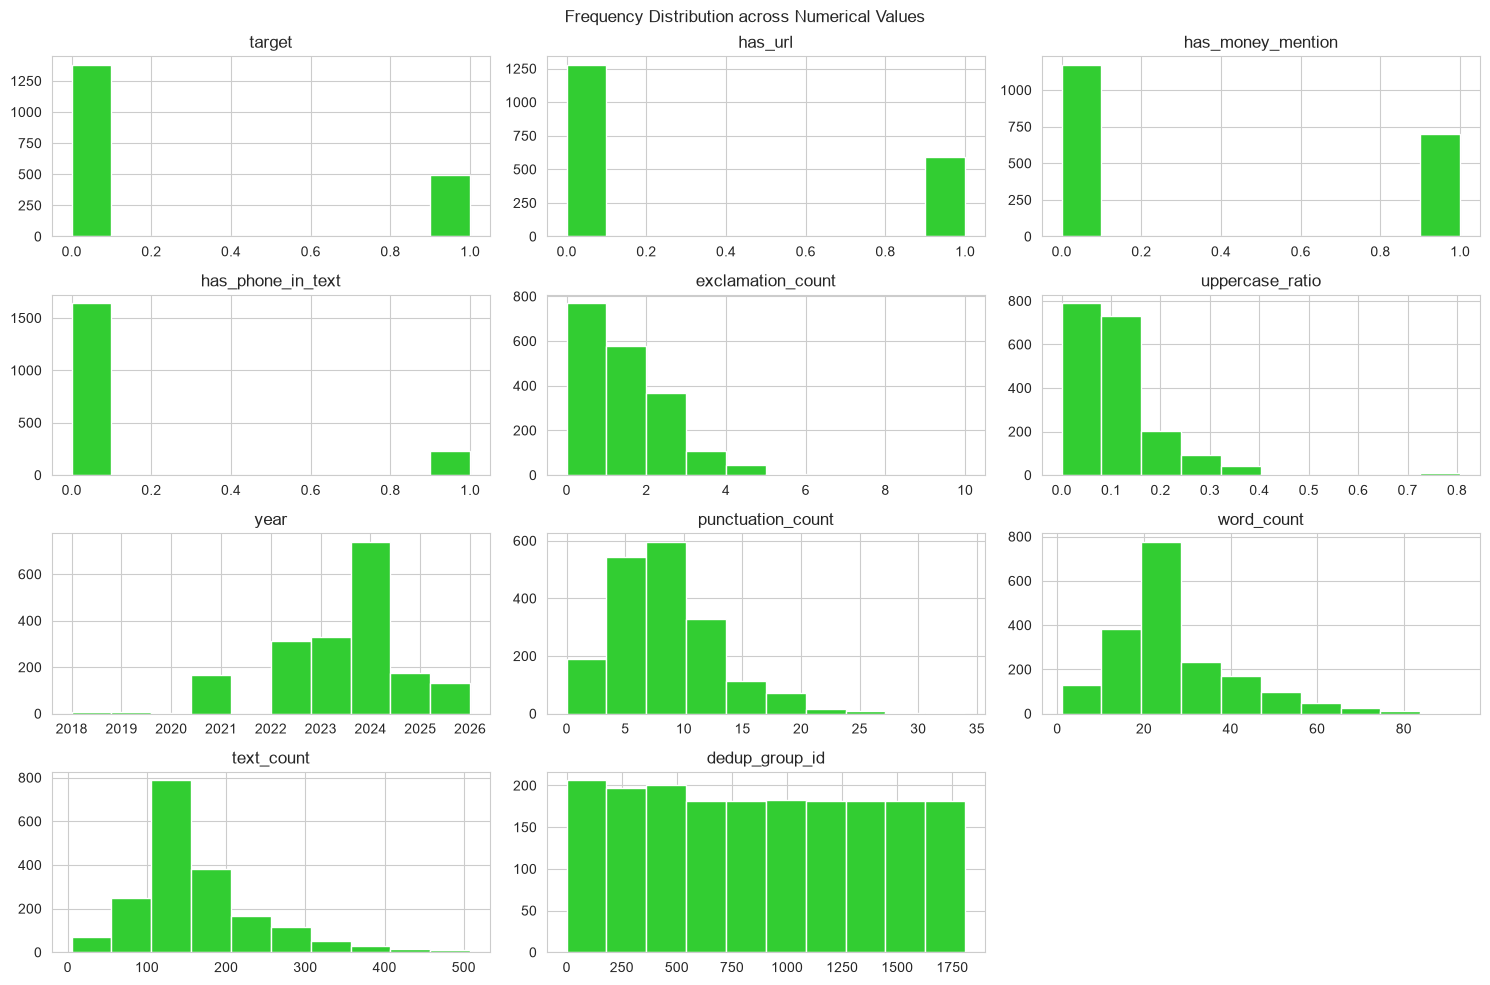

In [7]:
sns.set_style('whitegrid')
fig, ax = plt.subplots(figsize=(15, 10))

data = data.drop(columns=['date'])
data.hist(ax=ax, color='limegreen', edgecolor='white')
plt.suptitle('Frequency Distribution across Numerical Values')
plt.tight_layout()

## Correlation Heatmap

Text(0.5, 1.0, 'Correlation Heatmap')

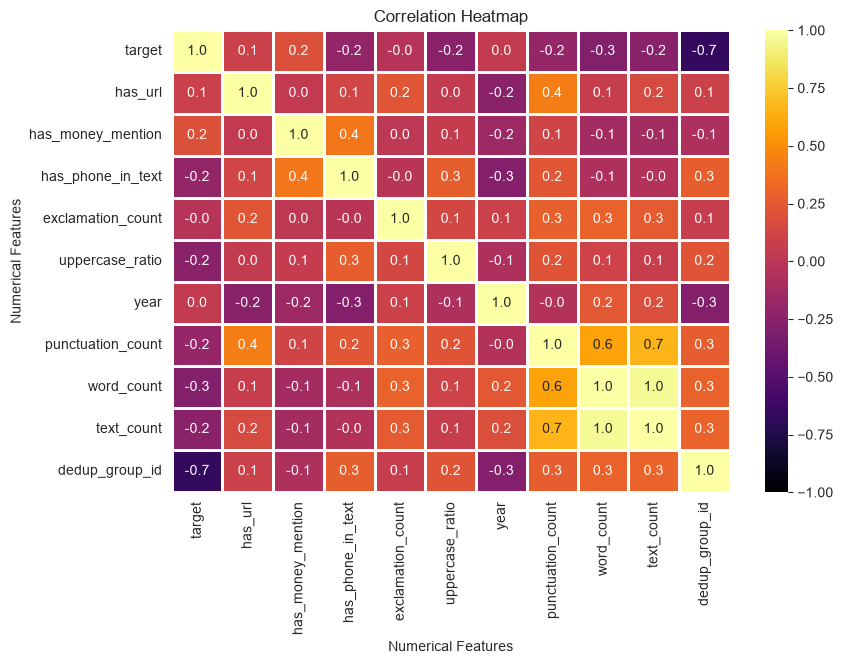

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(data.corr(numeric_only=True), annot=True, fmt='.1f',
            cmap='inferno', linecolor='white', vmin=-1, vmax=1, linewidths=1, ax=ax)

ax.set_ylabel('Numerical Features')
ax.set_xlabel('Numerical Features')
ax.set_title('Correlation Heatmap')

## Feature Significance (Correlation with Label)

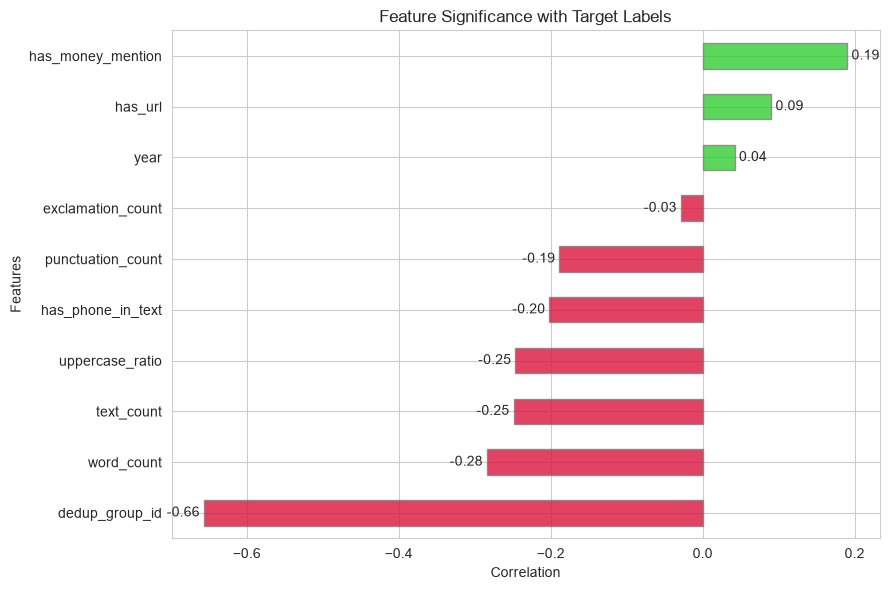

In [9]:
feats_sig = data.corr(numeric_only=True)['target'].drop('target')
feats_sig = feats_sig.sort_values()

fig, ax = plt.subplots(figsize=(9, 6))

labels = ['crimson' if corr < 0 else 'limegreen' for corr in feats_sig]
feats_sig.plot(kind='barh', color=labels, ax=ax, edgecolor='gray', alpha=0.8)
ax.set_ylabel('Features')
ax.set_xlabel('Correlation')
ax.set_title('Feature Significance with Target Labels')

ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)
plt.tight_layout()

## Categorical Counts

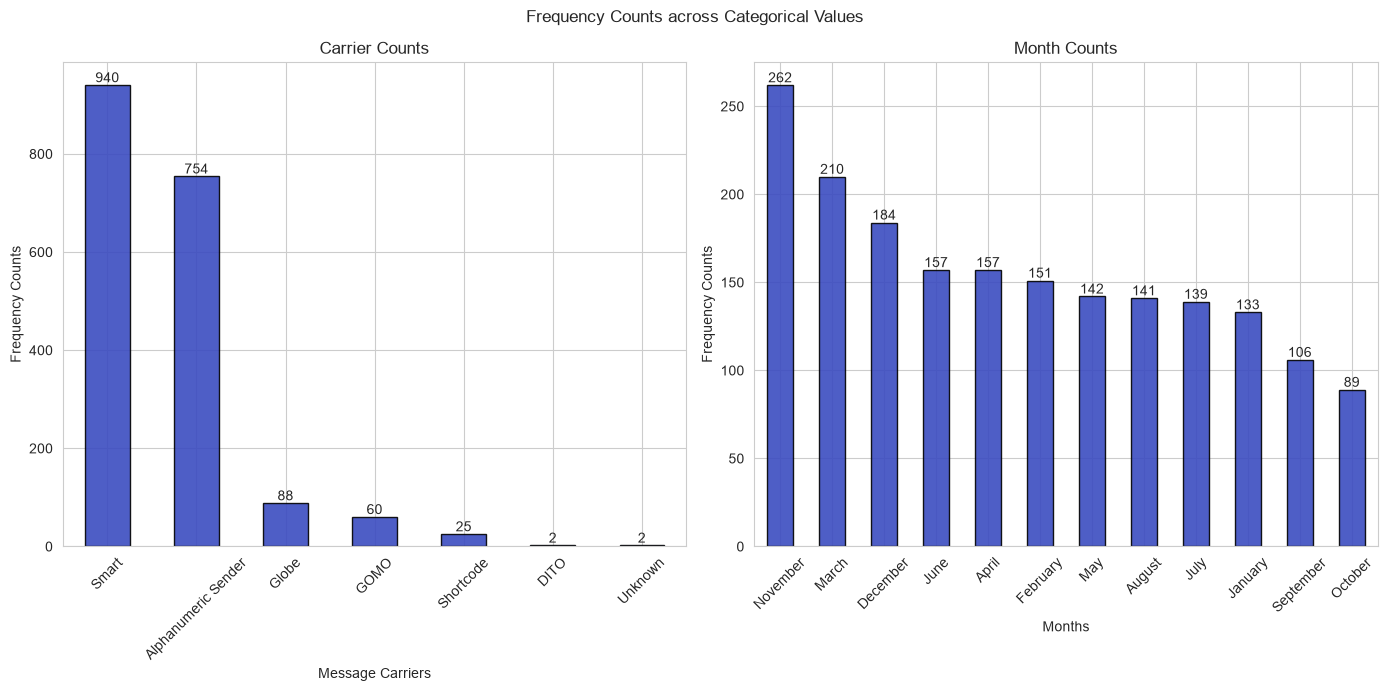

In [10]:
import calendar
cats = data.select_dtypes(include=['object', 'string'])
fig, ax = plt.subplots(1, 2, figsize=(14, 7))

category = cats['carrier'].value_counts().sort_values(ascending=False)
category.plot(kind='bar', ax=ax[0], edgecolor='black', alpha=0.9, cmap='coolwarm')
ax[0].set_title('Carrier Counts')

months_counts = cats['month'].value_counts()
months_counts.plot(kind='bar', ax=ax[1], edgecolor='black', alpha=0.9, cmap='coolwarm')
ax[1].set_title('Month Counts')

ax[0].set_xlabel('Message Carriers')
ax[1].set_xlabel('Months')

for axes in ax:
    axes.set_ylabel('Frequency Counts')
    axes.bar_label(axes.containers[0])
    axes.tick_params(axis='x', rotation=45)


plt.suptitle('Frequency Counts across Categorical Values')
plt.tight_layout()


target
0    73.76
1    26.24
Name: proportion, dtype: float64


[Text(0, 0, '1380'), Text(0, 0, '491')]

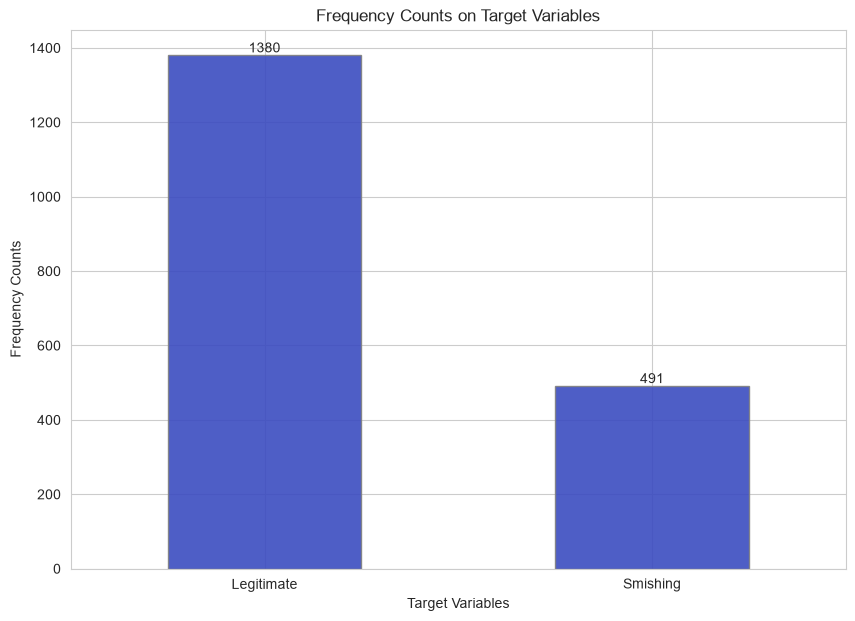

In [11]:
# target labels
print(np.round(data['target'].value_counts(normalize=True) * 100, 2))

targets = data['target'].value_counts().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 7))
targets.plot(kind='bar', ax=ax, alpha=0.9, edgecolor='gray', cmap='coolwarm')
ax.set_xlabel('Target Variables')
ax.set_ylabel('Frequency Counts')
ax.set_xticklabels(['Legitimate', 'Smishing'])
ax.set_title('Frequency Counts on Target Variables')
ax.tick_params(axis='x', rotation=0)
ax.bar_label(ax.containers[0])

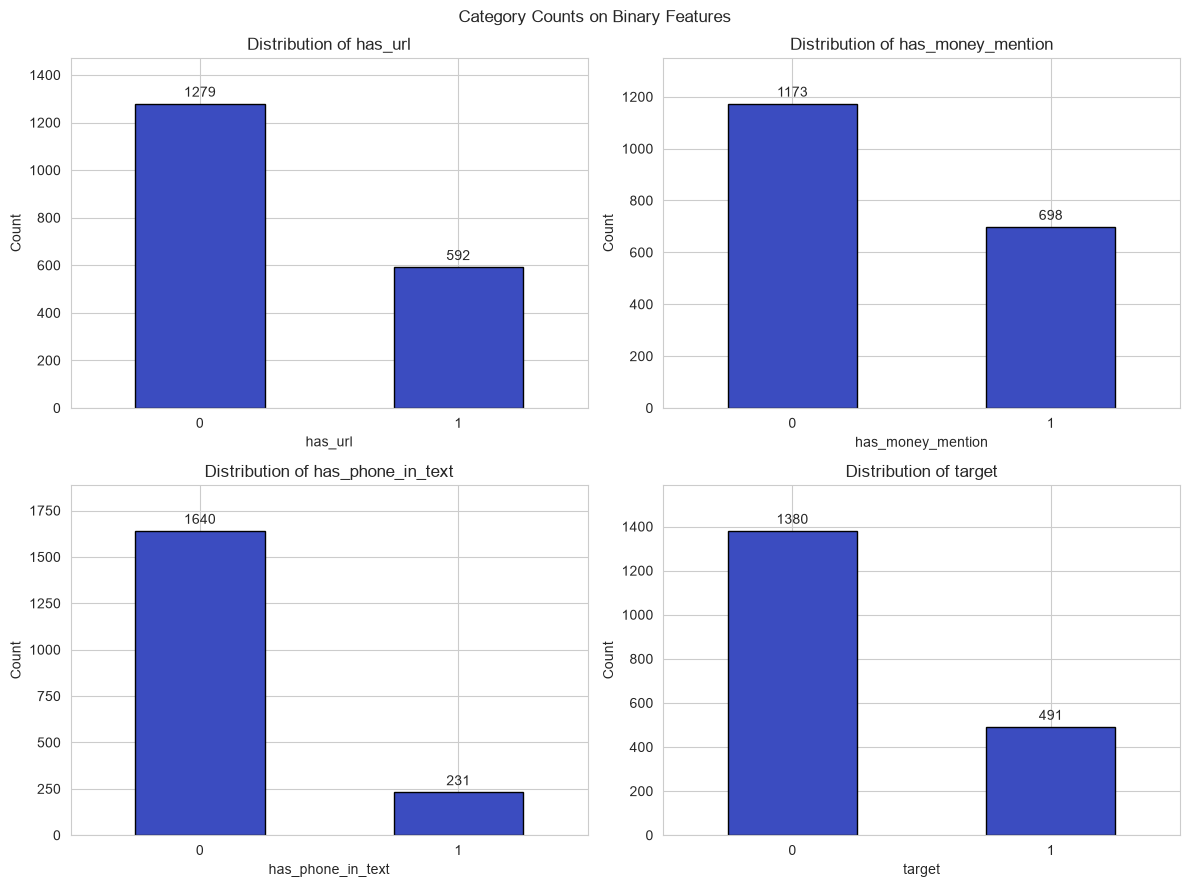

In [12]:
columns = ['has_url', 'has_money_mention', 'has_phone_in_text', 'target']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes = axes.flatten()

for i, col in enumerate(columns):

    binary_counts = data[col].value_counts().sort_values(ascending=False)

    binary_counts.plot(
        kind='bar', 
        ax=axes[i], 
        cmap='coolwarm', 
        edgecolor='black'
    )
    
    axes[i].set_title(f'Distribution of {col}')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].set_ylabel('Count')
    axes[i].bar_label(axes[i].containers[0], padding=3)
    axes[i].set_ylim(0, max(binary_counts) * 1.15)

plt.suptitle('Category Counts on Binary Features')
plt.tight_layout()

## Outlier Detection

In [13]:
numerical_cols = [
    'punctuation_count', 'text_count', 'has_url', 'has_money_mention',
    'has_phone_in_text', 'exclamation_count', 'uppercase_ratio', 'word_count']
lower_quantile = data[numerical_cols].quantile(0.25)
upper_quantile = data[numerical_cols].quantile(0.75)

iqr = upper_quantile - lower_quantile
lower_bound = lower_quantile - 1.5 * iqr
upper_bound = upper_quantile + 1.5 * iqr

outlier_mask = (data[numerical_cols] < lower_bound) | (data[numerical_cols] > upper_bound)
outliers = data[outlier_mask.any(axis=1)]

outliers

,text,carrier,target,has_url,has_money_mention,has_phone_in_text,exclamation_count,uppercase_ratio,year,month,punctuation_count,word_count,text_count,dedup_group_id
3,fex parcel p iisddcddtba reach contact branch ...,Smart,1,0,0,1,0,0.119266,2025,August,5,16,109,3
18,miss bdo fixed rate asean sustainability bonds...,Alphanumeric Sender,0,0,0,0,2,0.165289,2025,July,22,54,362,9
28,bdo update new bdo online app update required ...,Alphanumeric Sender,0,1,0,0,0,0.072674,2025,January,15,52,344,13
54,received applying credit card annual fee life ...,Smart,1,0,0,1,0,0.104575,2024,June,6,54,304,39
72,greetings bdo continuous effort bring best onl...,Smart,1,0,0,0,0,0.030100,2024,June,8,48,299,56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1869,just ya gomo fam free upsize pickup coffee gom...,GOMO,0,1,0,0,1,0.194203,2026,November,16,60,345,1798
1870,cozy gomo fam perk free upsize pickup coffee d...,GOMO,0,0,0,0,1,0.208609,2026,November,10,54,302,1799
1875,share time pin gomo otp,GOMO,0,0,0,0,0,0.581818,2026,November,3,10,55,1804
1876,flash deal aduna moneytoken unli internet gika...,Globe,0,0,0,0,4,0.129032,2026,November,16,67,403,1805


In [14]:
len(outliers) / len(data) * 100

25.494388027792624

In [15]:
# pca outlier detection projected in a 2D scatter

scaler = StandardScaler()

pca_data = data[numerical_cols]
scaled_data = scaler.fit_transform(pca_data)

pca = PCA(n_components=0.85, random_state=42)
pca_components = pca.fit_transform(scaled_data)
pca.fit(scaled_data)

components = pd.DataFrame({
    'PrincipalComponent1' : pca_components[:, 0],
    'PrincipalComponent2' : pca_components[:, 1],
    'PrincipalComponent3' : pca_components[:, 2],
    'PrincipalComponent4' : pca_components[:, 3],
    'PrincipalComponent5' : pca_components[:, 4]
})

components['is_outlier'] = outlier_mask.any(axis=1).values

print(f"Variance per Component: {pca.explained_variance_ratio_}")
print(f"Cumulative Explained Var Ratio: {np.sum(pca.explained_variance_ratio_)}")

Variance per Component: [0.34601234 0.20446778 0.12848627 0.11789837 0.0998534 ]
Cumulative Explained Var Ratio: 0.8967181649836253


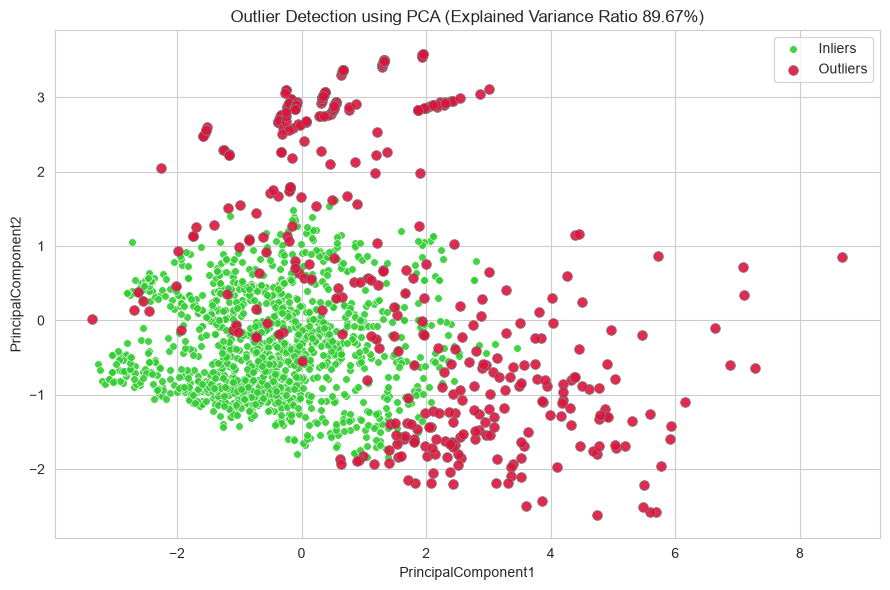

In [16]:
sns.set_style('whitegrid')

fig, ax = plt.subplots(figsize=(9, 6))

labels = ['Inliers', 'Outliers']

sns.scatterplot(data=components[components['is_outlier'] == False], x='PrincipalComponent1',
                y='PrincipalComponent2', alpha=0.9,
                color='limegreen', ax=ax, s=30)

sns.scatterplot(data=components[components['is_outlier'] == True], x='PrincipalComponent1',
                y='PrincipalComponent2', alpha=0.9,
                color='crimson', ax=ax, edgecolor='gray', s=50)

ax.set_title('Outlier Detection using PCA (Explained Variance Ratio 89.67%)')
plt.legend(labels)

plt.tight_layout()

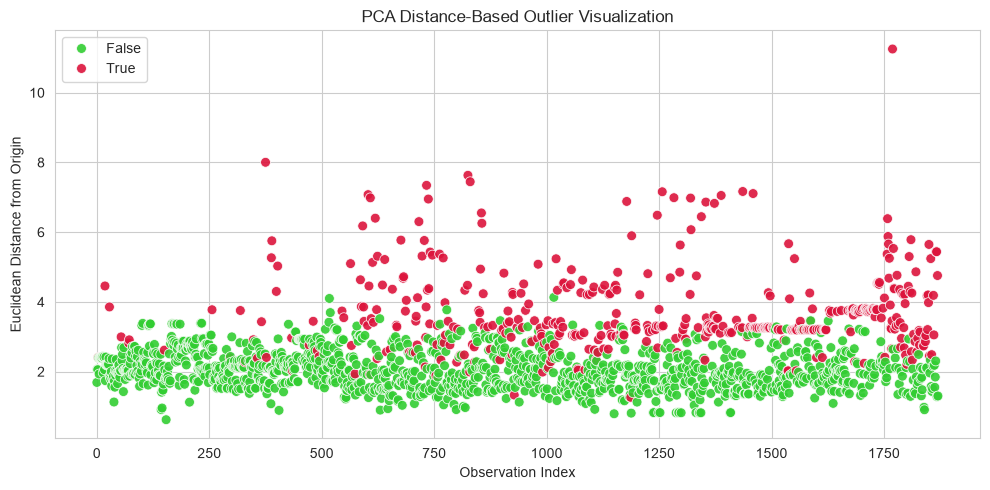

In [17]:
components['pca_distance'] = np.sqrt(
    np.sum(pca_components ** 2, axis=1)
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.scatterplot(
    data=components,
    x=components.index,
    y='pca_distance',
    hue='is_outlier',
    palette={
        False: 'limegreen',
        True: 'crimson'
    },
    alpha=0.9,
    ax=ax,
    s=50
)

ax.set_title('PCA Distance-Based Outlier Visualization')
ax.set_xlabel('Observation Index')
ax.set_ylabel('Euclidean Distance from Origin')
ax.legend()

plt.tight_layout()
plt.show()

## Aggregated Tables and Visualizations

In [18]:
# smishing counts per carriers

targets_per_carriers = data.groupby('carrier').agg(
    total_messages_per_carrier = ('target', 'count')
)
print(targets_per_carriers)
print(f"Total Messages: {len(data)}")

                     total_messages_per_carrier
carrier                                        
Alphanumeric Sender                         754
DITO                                          2
GOMO                                         60
Globe                                        88
Shortcode                                    25
Smart                                       940
Unknown                                       2
Total Messages: 1871


In [19]:
cross = pd.crosstab(
    index=data['carrier'],
    columns=data['target'],
    rownames=['Carrier'],
    colnames=['Target (0=Legitimate, 1=Smishing)']
)

target_per_carriers = cross
print(target_per_carriers)

Target (0=Legitimate, 1=Smishing)    0    1
Carrier                                    
Alphanumeric Sender                747    7
DITO                                 1    1
GOMO                                60    0
Globe                               83    5
Shortcode                           25    0
Smart                              462  478
Unknown                              2    0


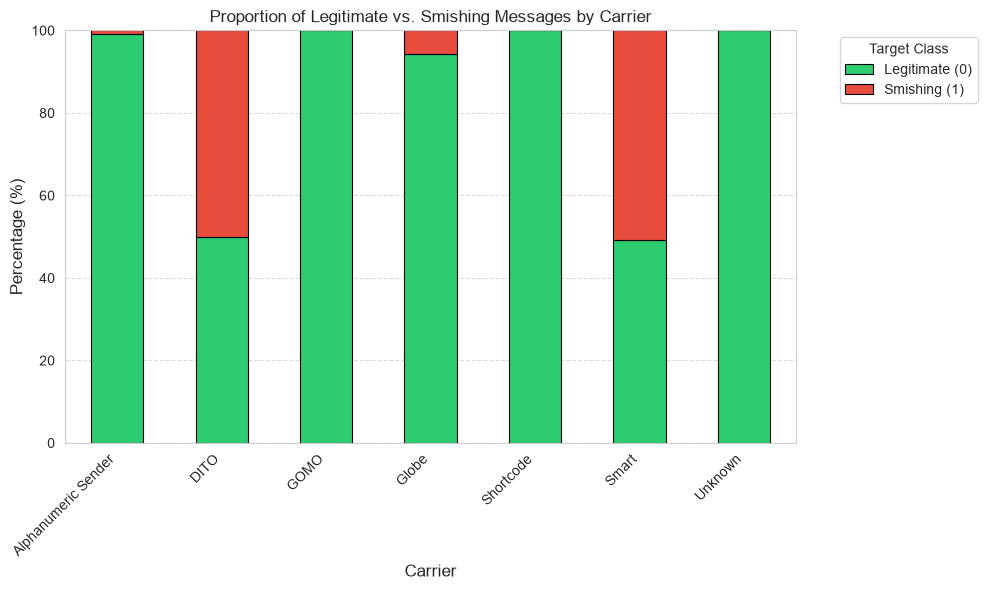

In [20]:
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100


fig, ax = plt.subplots(figsize=(10, 6))
cross_pct.plot(
    kind='bar', 
    stacked=True, 
    ax=ax, 
    color=['#2ecc71', '#e74c3c'],
    edgecolor='black',
    linewidth=0.8
)

plt.title('Proportion of Legitimate vs. Smishing Messages by Carrier')
plt.xlabel('Carrier', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.legend(['Legitimate (0)', 'Smishing (1)'], title='Target Class', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

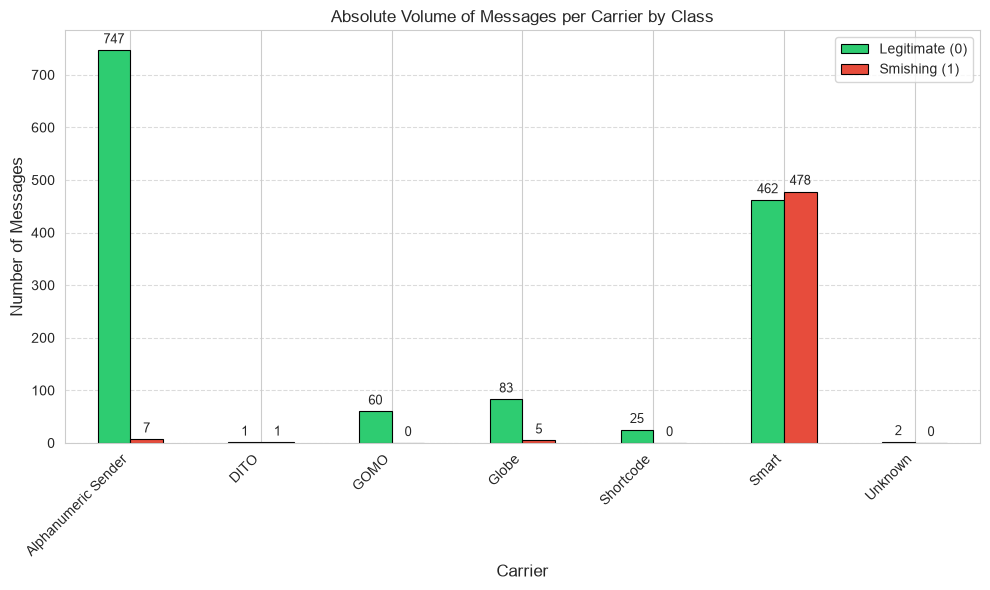

In [21]:
cross = pd.crosstab(
    index=data['carrier'],
    columns=data['target']
)
cross.columns = ['Legitimate (0)', 'Smishing (1)']

fig, ax = plt.subplots(figsize=(10, 6))
cross.plot(
    kind='bar', 
    stacked=False, 
    ax=ax, 
    color=['#2ecc71', '#e74c3c'],
    edgecolor='black',
    linewidth=0.8
)

plt.title('Absolute Volume of Messages per Carrier by Class')
plt.xlabel('Carrier', fontsize=12)
plt.ylabel('Number of Messages', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)

plt.tight_layout()
plt.show()

In [22]:
# average instances of money mentioned/url per target

money_mentioned_by_target = data.groupby('target').agg({'has_money_mention' : 'mean'})
print(money_mentioned_by_target * 100)

        has_money_mention
target                   
0               31.811594
1               52.749491


In [23]:
url_per_target = data.groupby('target').agg({'has_url' : 'mean'})
print(url_per_target * 100)

          has_url
target           
0       29.130435
1       38.696538


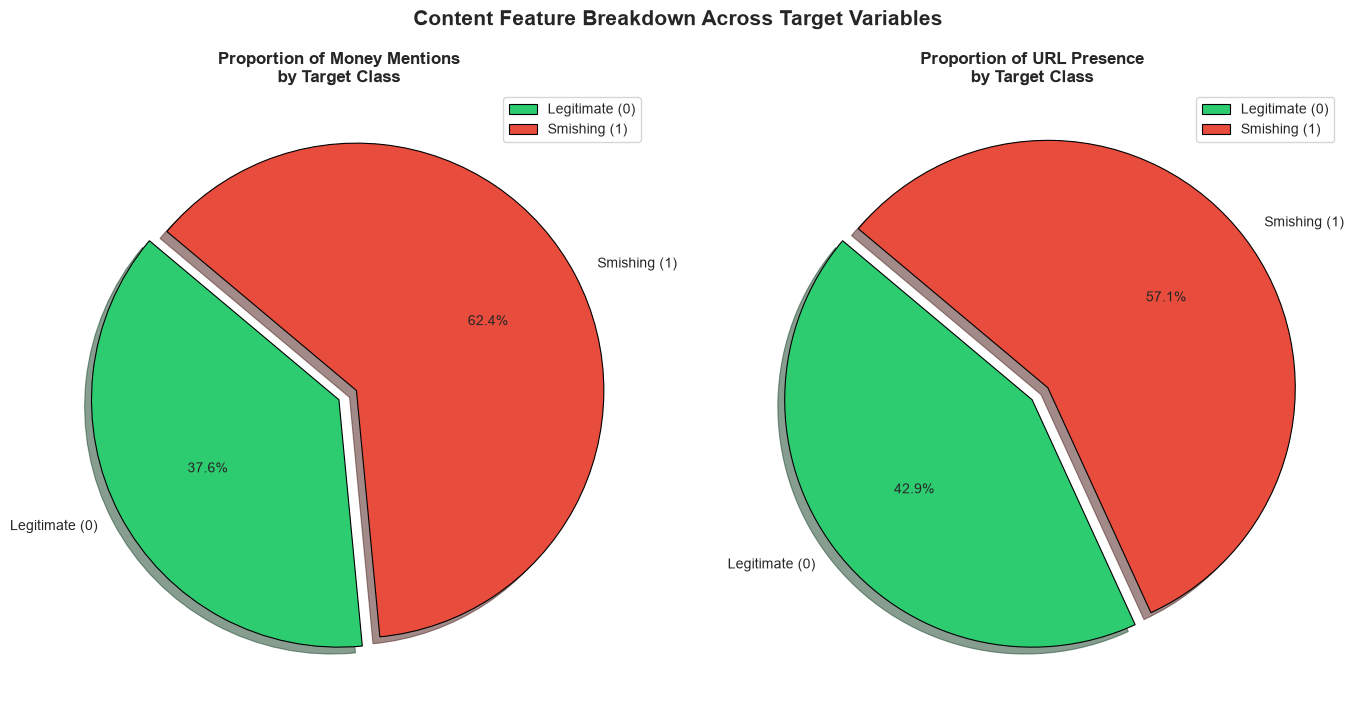

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7))

money_mentioned_by_target.plot(
    kind='pie', y='has_money_mention', ax=ax[0],
    labels=['Legitimate (0)', 'Smishing (1)'], autopct='%1.1f%%',
    startangle=140, colors=['#2ecc71', '#e74c3c'], shadow=True, explode=(0, 0.08), 
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.8})

ax[0].set_title('Proportion of Money Mentions\nby Target Class', fontsize=12, fontweight='bold')

url_per_target.plot(
    kind='pie',
    y='has_url',
    ax=ax[1],
    labels=['Legitimate (0)', 'Smishing (1)'], explode=(0, 0.08), 
    autopct='%1.1f%%',
    shadow=True,
    startangle=140,
    colors=['#2ecc71', '#e74c3c'],
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.8}
)
ax[1].set_title('Proportion of URL Presence\nby Target Class', fontsize=12, fontweight='bold')

for axes in ax:
    axes.set_ylabel('')

plt.suptitle('Content Feature Breakdown Across Target Variables', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()

## Word Cloud in Smishing and Legitimate Texts

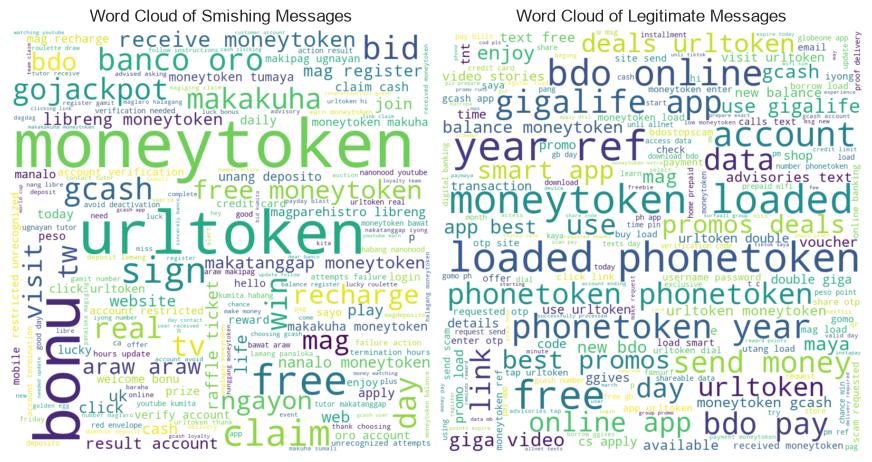

In [25]:
smish = data[data['target'] == 1]
legit = data[data['target'] == 0]

smish_texts = " ".join(smish['text'].dropna().astype(str))
legit_texts = " ".join(legit['text'].dropna().astype(str))

smishing_word_cloud = WordCloud(
    width=800, height=800,
    background_color='white', min_font_size=10).generate(smish_texts)

legitimate_word_cloud = WordCloud(
    width=800, height=800,
    background_color='white', min_font_size=10).generate(legit_texts)

fig, ax = plt.subplots(1, 2, figsize=(11, 8), facecolor=None)
ax[0].imshow(smishing_word_cloud, interpolation='bilinear')
ax[1].imshow(legitimate_word_cloud, interpolation='bilinear')

for axes in ax:
    axes.axis('off')

ax[0].set_title('Word Cloud of Smishing Messages')
ax[1].set_title('Word Cloud of Legitimate Messages')
plt.subplots_adjust(wspace=0.02) 